In [1]:
import pandas as pd
from pathlib import Path

# now we save the data into a Pandas data fram 
# Define all 26 columns in the data se
columns = (["unit_id", "cycle"] + [f"setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)])

# Find the extracted files
data_dir = Path("data")

train_path = next(data_dir.rglob("train_FD004.txt"))
test_path = next(data_dir.rglob("test_FD004.txt"))
rul_path = next(data_dir.rglob("RUL_FD004.txt"))

# Load training and testing data
train_df = pd.read_csv(train_path, sep = r"\s+", header = None, names = columns)

test_df = pd.read_csv(test_path,sep = r"\s+",header = None, names = columns)

# True RUL for each test engine
rul_df = pd.read_csv(rul_path,sep = r"\s+",header = None, names = ["RUL"])

print(train_df.head())
print(train_df.shape)

   unit_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0        1      1    42.0049     0.8400      100.0    445.00    549.68   
1        1      2    20.0020     0.7002      100.0    491.19    606.07   
2        1      3    42.0038     0.8409      100.0    445.00    548.95   
3        1      4    42.0000     0.8400      100.0    445.00    548.70   
4        1      5    25.0063     0.6207       60.0    462.54    536.10   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1343.43   1112.93      3.91  ...     129.78    2387.99    8074.83   
1   1477.61   1237.50      9.35  ...     312.59    2387.73    8046.13   
2   1343.12   1117.05      3.91  ...     129.62    2387.97    8066.62   
3   1341.24   1118.03      3.91  ...     129.80    2388.02    8076.05   
4   1255.23   1033.59      7.05  ...     164.11    2028.08    7865.80   

   sensor_15  sensor_16  sensor_17  sensor_18  sensor_19  sensor_20  sensor_21  
0     9.3335       0.02        330 

In [2]:
# Find failure cycle of each training engine
# group the train data together for each unit type and by cycle and find the maximum cycle which is the last cycle recorded
max_cycles = train_df.groupby("unit_id")["cycle"].transform("max")

# Calculate RUL and add to the data frame 
# RUL is the max cycle - current cycle
train_df["RUL"] = max_cycles - train_df["cycle"]

print(train_df[["unit_id", "cycle", "RUL"]].head())

   unit_id  cycle  RUL
0        1      1  320
1        1      2  319
2        1      3  318
3        1      4  317
4        1      5  316


In [3]:
# We only want to keep the final measurement for testing  
test_final = (test_df.sort_values(["unit_id", "cycle"]).groupby("unit_id").tail(1).sort_values("unit_id").reset_index(drop = True))

# Add true test RUL from the rul file there is only one value for each engine so we can append
test_final["RUL"] = rul_df["RUL"]

print(test_final[["unit_id", "cycle", "RUL"]].head())

   unit_id  cycle  RUL
0        1    230   22
1        2    153   39
2        3    141  107
3        4    208   75
4        5     51  149


unit_id      0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
RUL          0
dtype: int64


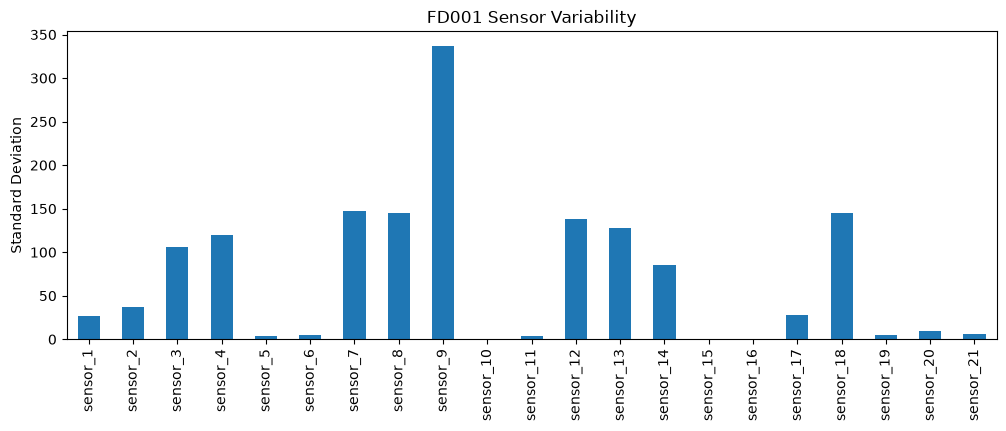

In [4]:
import matplotlib.pyplot as plt

# for CMAPSS it is important to remove any sensors that don't contribute to learning
# sensors that don't change can be removed for analysis 

sensor_cols = []
for i in range(1, 22):
    sensor_cols.append(f"sensor_{i}")

# Check missing values
print(train_df.isnull().sum())

# Examine sensor variability higher varaibility means change lower or zero means no change
sensor_std = train_df[sensor_cols].std()

# Visualize the sensor standard deviations
sensor_std.plot(kind = "bar", figsize=(12, 4))
plt.ylabel("Standard Deviation")
plt.title("FD001 Sensor Variability")
plt.show()

In [5]:
# Keep the same FD001 sensor subset for a direct baseline comparison.
# For multi-condition datasets (FD002/FD004), regime-aware normalization is a useful follow-up experiment. 
selected_sensors = [
    "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5", "sensor_6",
    "sensor_7", "sensor_8", "sensor_9",
    "sensor_11", "sensor_12", "sensor_13",
    "sensor_14", "sensor_17", "sensor_18", "sensor_19",
    "sensor_20", "sensor_21"
]

from sklearn.model_selection import train_test_split

# now we can prepare the data by splitting into train and validation sets
# then normalize the data 

engine_ids = train_df["unit_id"].unique()

# 80% training , 20% validation 
# we need to split based on engine id because because rows from the same engine are
# highly correlated splitting by row would put some of an engine's cycles in
# training and others in validation, which would leak information 

train_ids, val_ids = train_test_split(engine_ids, test_size = 0.2, random_state = 42, shuffle = True)

# Create the separate datasets
train_data = train_df[train_df["unit_id"].isin(train_ids)].copy()
val_data = train_df[train_df["unit_id"].isin(val_ids)].copy()

print("Training engines:", train_data["unit_id"].nunique())
print("Validation engines:", val_data["unit_id"].nunique())

Training engines: 199
Validation engines: 50


In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# For most machine learning applciations we have to normalize our data
# use standard scaler for this which subtracts the mean and divides by the std

# use the selected engines only
train_data[selected_sensors] = scaler.fit_transform(train_data[selected_sensors])
val_data[selected_sensors] = scaler.transform(val_data[selected_sensors])

# Normalize test data with the standard scaler
test_data = test_df.copy()
test_data[selected_sensors] = scaler.transform(test_data[selected_sensors])

In [7]:
import numpy as np

# LSTM requires sequences to be fed not just a single input vector 
# The sequence window we will use is 50 cycles, so we create many of these sequences incrementing by 1, each with a RUL target of cycles 

def create_sequences(df, features, window_size):
    """
    This function generates a sequence for LSTM training, where each sequence belongs to one engine
    The label is the RUL at its final cycle

    Parameters:
    df: The data frame we will use for creating the sequence
    features: The selected features we want to retain
    window_size: How many cycles we will put into one sequence

    Returns:
    X, y: The feature and target matrix and vector for the sequences of one engine
    """

    # build the feature and targets empty arrays
    X, y = [], []

    # group by each engine type creating seperate manipulatble df for each engine

    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.sort_values("cycle")

        # we need features for the X matrix and RUL cycles for the target y so we convert the needed values into numpy arrays
        sensor_data = engine[features].to_numpy(dtype = np.float32)
        rul_data = engine["RUL"].to_numpy(dtype = np.float32)

        # now make the sequences from the window size to the end of the data 
        # each sequence gets appended to X and y which are matrix and single values
        for end in range(window_size, len(engine) + 1):
            start = end - window_size

            # we want to retain a sequence window from start to end
            X.append(sensor_data[start:end])
            y.append(rul_data[end - 1])

    # use asarray to return a 3D tensor 
    return (np.asarray(X), np.asarray(y))

window_size = 50

# From online resources it seems that a common practice is to cap early-life RUL to avoid asking the model to distinguish very large RUL values from almost-healthy sensor readings
RUL_CAP = 125
if RUL_CAP is not None:
    train_data["RUL"] = train_data["RUL"].clip(upper = RUL_CAP)
    val_data["RUL"] = val_data["RUL"].clip(upper = RUL_CAP)

# create the sequence for training
X_train, y_train = create_sequences(train_data, selected_sensors, window_size)
X_val, y_val = create_sequences(val_data, selected_sensors, window_size)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

# since we train on sequences we also need to test on sequences
# use the same code but no feature
def create_test_sequences(df, features, window_size):
    X = []

    for engine_id, engine in df.groupby("unit_id"):
        engine = engine.sort_values("cycle")

        sensor_data = engine[features].to_numpy(dtype = np.float32)

        # Take last 50 cycles
        sequence = sensor_data[-window_size:]

        # If the the number of observations is less than 50 cycles then we will replace the remaing values with the first row 
        # this ensures that we maintain the correct window size
        if len(sequence) < window_size:
            padding = np.repeat(sequence[:1], window_size - len(sequence), axis = 0)
            sequence = np.vstack([padding, sequence])

        X.append(sequence)

    return np.asarray(X)


X_test = create_test_sequences(test_data, selected_sensors, window_size)

# Test labels correspond to the final cycle of each engine
y_test = rul_df["RUL"].to_numpy()

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (39543, 50, 18)
y_train: (39543,)
X_val: (9505, 50, 18)
y_val: (9505,)
X_test: (248, 50, 18)
y_test: (248,)


In [8]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Sklearn does not have a LSTM model however Pytorch does
# so we want to convery everything into pytorch tensors 

BATCH_SIZE = 64

# pair the data sets in pytorch frames
train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train),)
val_dataset = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val),)

# we want to shuffle our training data set so that the model does not see the same pattern every epoch
train_loader = DataLoader(train_dataset, batch_size = BATCH_SIZE, shuffle = True)
val_loader = DataLoader(val_dataset, batch_size = BATCH_SIZE, shuffle = False)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 618
Number of validation batches: 149


## LSTM training and evaluation

In [9]:
import random
import copy
from pathlib import Path
import torch.nn as nn

# now we build the LSTM model with pytorch 
# use a random seed 

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# First define the LSTM class

class RULLSTM(nn.Module):
    # we plan on using two hidden layers of size 64
    # dropout is set to 0.2 to help reduce over fitting setting some values to 0 when moving layers

    def __init__(self, input_size, hidden_size = 64, num_layers = 2, dropout = 0.2):
        super().__init__()

        # using the pytorch neural network LSTM library we define the LSTM 
        self.lstm = nn.LSTM(
            input_size = input_size,
            hidden_size = hidden_size,
            num_layers = num_layers,
            dropout = dropout if num_layers > 1 else 0.0,
            batch_first = True,
        )
        self.regressor = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        # x: (batch_size, window_size, number_of_sensors)
        outputs, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]  # final time step of the top LSTM layer
        return self.regressor(last_hidden).squeeze(-1)

model = RULLSTM(input_size = len(selected_sensors)).to(device)
print(model)

Using device: cpu
RULLSTM(
  (lstm): LSTM(18, 64, num_layers=2, batch_first=True, dropout=0.2)
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [10]:
import copy
# Train using MSE; report RMSE in cycles for interpretability.
# Define the parameters 
# Early stopping will be implemented to help against overfitting so lets set Patience to 12 so that if it does not improve in 12 epochs we stop
EPOCHS = 80
LEARNING_RATE = 1e-3
PATIENCE = 12
criterion = nn.MSELoss()

# use Adam as the optimizer
optimizer = torch.optim.Adam(model.parameters(), lr = LEARNING_RATE, weight_decay = 1e-5)

def run_epoch(loader, training = False):
    ''' 
    This function defines a single epoch run of the LSTM RNN
    '''
    model.train(mode = training)
    squared_error_sum = 0.0
    count = 0

    # loop through the batches in loader

    for x_batch, y_batch in loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        # during training we set the gradients to zero to clear the older gradients
        if training:
            optimizer.zero_grad(set_to_none = True)

        with torch.set_grad_enabled(training):
            prediction = model(x_batch)
            # compute loss
            loss = criterion(prediction, y_batch)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm = 1.0)
                # update weights
                optimizer.step()

        # compute the squared error
        squared_error_sum += ((prediction.detach() - y_batch) ** 2).sum().item()
        count += y_batch.numel()

    return (squared_error_sum / count) ** 0.5

# We wanted to visualize the training and print the training history 
# so we store in a dictionary
history = {"train_rmse": [], "val_rmse": []}
best_val_rmse = float("inf")
best_state = None
best_epoch = 0
stale_epochs = 0

# train for the number of required epochs 
for epoch in range(1, EPOCHS + 1):
    train_rmse = run_epoch(train_loader, training = True)
    val_rmse = run_epoch(val_loader, training = False)

    history["train_rmse"].append(train_rmse)
    history["val_rmse"].append(val_rmse)

    # if the validation RMSE improves we update our values in regards to the best epoch and best val_rmse
    if val_rmse < best_val_rmse - 1e-4:
        best_val_rmse = val_rmse
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        stale_epochs = 0
    # if the validation rmse does not improve we update the stale epoch count until it reaches the patience level
    else:
        stale_epochs += 1

    # print the learning cycles
    if epoch == 1 or epoch % 5 == 0 or stale_epochs >= PATIENCE:
        print(f"Epoch {epoch:3d}: train RMSE = {train_rmse:.3f}, "f"validation RMSE = {val_rmse:.3f} cycles")

    # if the epochs dont improve above the patience level we stop for early stopping.
    if stale_epochs >= PATIENCE:
        print("Early stopping: validation RMSE did not improve.")
        break

if best_state is None:
    raise RuntimeError("No successful epoch")

model.load_state_dict(best_state)
print(f"Best validation RMSE: {best_val_rmse:.3f} cycles, epoch {best_epoch}")

Epoch   1: train RMSE = 57.847, validation RMSE = 40.056 cycles
Epoch   5: train RMSE = 16.523, validation RMSE = 20.356 cycles
Epoch  10: train RMSE = 13.744, validation RMSE = 19.658 cycles
Epoch  15: train RMSE = 10.482, validation RMSE = 21.343 cycles
Epoch  18: train RMSE = 8.492, validation RMSE = 22.799 cycles
Early stopping: validation RMSE did not improve.
Best validation RMSE: 19.282 cycles, epoch 6


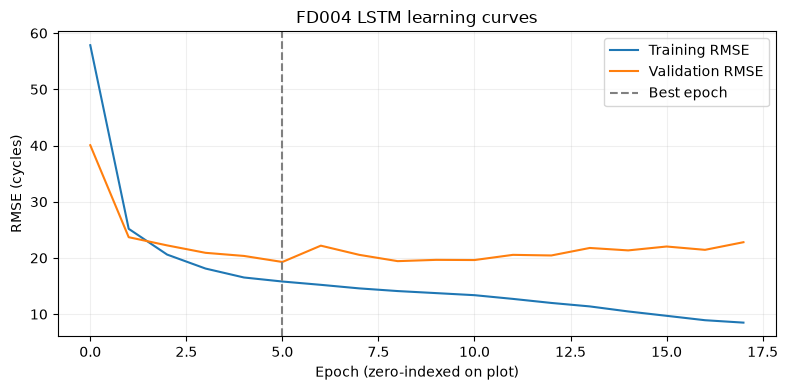

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(history["train_rmse"], label="Training RMSE")
plt.plot(history["val_rmse"], label="Validation RMSE")
plt.axvline(best_epoch - 1, linestyle="--", color="gray", label="Best epoch")
plt.xlabel("Epoch (zero-indexed on plot)")
plt.ylabel("RMSE (cycles)")
plt.title("FD004 LSTM learning curves")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [12]:
# Evaluate the model once after selecting the model by validation performance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def predict_in_batches(model, X, batch_size = 512):
    ''' 
    This function 
    '''
    model.eval()
    preds = []
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            batch = torch.from_numpy(X[start:start + batch_size]).to(device)
            preds.append(model(batch).cpu().numpy())
    return np.concatenate(preds)

def nasa_phm08_score(y_true, y_pred):
    ''' 
    This function defines the NASA penalty for the 2008 competition which penalizes late predictions more
    '''
    error = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.where(error < 0, np.exp(-error / 13.0) - 1.0, np.exp(error / 10.0) - 1.0).sum())

# Negative RUL is not physically meaningful so we retain nonnegative predictions
y_pred = np.maximum(predict_in_batches(model, X_test), 0.0)

# compute the rmse, mse r2, and the score for the test data set
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
score = nasa_phm08_score(y_test, y_pred)

print(f"Test RMSE: {rmse:.3f} cycles")
print(f"Test MAE: {mae:.3f} cycles")
print(f"Test R²: {r2:.3f}")
print(f"NASA asymmetric score: {score:.3f} (lower is better)")

results_df = pd.DataFrame({
    "unit_id": sorted(test_data["unit_id"].unique()),
    "true_rul": y_test,
    "predicted_rul": y_pred,
    "error": y_pred - y_test,
})
display(results_df.head(10))

Test RMSE: 28.062 cycles
Test MAE: 20.435 cycles
Test R²: 0.735
NASA asymmetric score: 5627.633 (lower is better)


,unit_id,true_rul,predicted_rul,error
0,1,22,34.848709,12.848709
1,2,39,59.457886,20.457886
2,3,107,115.008331,8.008331
3,4,75,109.764816,34.764816
4,5,149,113.290253,-35.709747
5,6,78,119.160095,41.160095
6,7,94,109.766769,15.766769
7,8,14,15.204181,1.204181
8,9,99,113.658119,14.658119
9,10,162,123.912201,-38.087799
